# 03 · Modelo

Dos preguntas con el mismo método (`src/radar/modelo.py`):

1. **Radar**: con las reseñas de los días 3, 7 o 14, ¿cuántas tendrá el juego a los 30 días?
2. **Antes de lanzar**: con precio, género y mes, ¿se puede decir lo mismo?

Partición por fecha de lanzamiento (60 % entrenamiento, 20 % calibración, 20 % test con los juegos más recientes). El candidato se elige por validación cruzada temporal dentro del entrenamiento; el test se mira una sola vez. El rango del 90 % es conformal, calibrado en un bloque que el modelo no ha visto.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.inspection import permutation_importance

from radar import config
from radar import modelo as m

plt.rcParams.update({"figure.figsize": (8, 4), "axes.grid": True, "grid.alpha": 0.3})
ds = pd.read_csv(
    config.DIR_PROCESADO / "dataset_radar.csv", parse_dates=["fecha_lanzamiento"]
)
train, calib, test = m.particion_temporal(ds)
for nombre, parte in [("train", train), ("calibración", calib), ("test", test)]:
    print(
        f"{nombre:>12}: {len(parte):4d} juegos, {parte.fecha_lanzamiento.min():%Y-%m-%d} → {parte.fecha_lanzamiento.max():%Y-%m-%d}"
    )

       train: 1811 juegos, 2025-10-29 → 2026-05-14
 calibración:  604 juegos, 2026-05-14 → 2026-07-23
        test:  604 juegos, 2026-07-23 → 2026-09-09


## 1. Radar: comparación de candidatos

In [2]:
resultados = {
    d: m.entrenar(ds, m.variables_radar(d), columna_ratio=f"log_resenas_{d}d")
    for d in config.DIAS_LECTURA
}
cv = pd.concat([r.cv.assign(dia=d) for d, r in resultados.items()])
cv.pivot_table(
    index="modelo", columns="dia", values="mae_log", aggfunc=["mean", "std"]
).round(3)

mean                  std              
dia                   3      7      14     3      7      14
modelo                                                     
gradient_boosting  0.390  0.236  0.130  0.034  0.021  0.019
mediana            1.280  1.280  1.280  0.050  0.050  0.050
ratio_tipico       0.391  0.233  0.128  0.020  0.017  0.018
ridge              0.385  0.234  0.132  0.021  0.015  0.019

**Conclusión.** Con 1.811 lanzamientos de entrenamiento, los tres candidatos con información quedan muy juntos y muy lejos de la mediana (MAE 0,39 frente a 1,28 a día 3). Las diferencias entre ellos son menores que su desviación entre pliegues: a día 3 gana Ridge por poco (0,385); a días 7 y 14 gana el ratio típico (0,233 y 0,128), la regla simple. Se respeta lo que dice la validación aunque el elegido sea el modelo más sencillo: añadir complejidad que no mejora fuera de muestra solo añade riesgo.

## 2. Radar: resultado en test

In [3]:
filas = []
for d, r in resultados.items():
    filas.append({"día": d, "modelo": r.nombre, **r.test})
    for nombre, met in r.test_baselines.items():
        filas.append({"día": d, "modelo": nombre, **met})
pd.DataFrame(filas).set_index(["día", "modelo"]).round(3)

mae_log  mediana_error_log  factor_error_tipico  \
día modelo                                                               
3   ridge                0.341              0.290                1.336   
    mediana              1.212              0.872                2.392   
    ratio_tipico         0.358              0.288                1.333   
    gradient_boosting    0.332              0.258                1.294   
7   ratio_tipico         0.220              0.190                1.210   
    mediana              1.212              0.872                2.392   
    ridge                0.213              0.172                1.188   
    gradient_boosting    0.211              0.172                1.187   
14  ratio_tipico         0.113              0.087                1.091   
    mediana              1.212              0.872                2.392   
    ridge                0.114              0.091                1.095   
    gradient_boosting    0.113              0.087                1.091   

                       spearman  dentro_de_x2  cobertura_90  
día modelo                                                   
3   ridge                 0.948         0.919         0.932  
    mediana                 NaN         0.406           NaN  
    ratio_tipico          0.942         0.896           NaN  
    gradient_boosting     0.946         0.911           NaN  
7   ratio_tipico          0.974         0.980         0.920  
    mediana                 NaN         0.406           NaN  
    ridge                 0.976         0.980           NaN  
    gradient_boosting     0.975         0.980           NaN  
14  ratio_tipico          0.992         0.995         0.926  
    mediana                 NaN         0.406           NaN  
    ridge                 0.993         0.995           NaN  
    gradient_boosting     0.992         0.993           NaN

**Conclusión.** En los 604 lanzamientos más recientes, que ningún modelo vio, el radar se desvía en el juego típico un factor ×1,34 a día 3, ×1,21 a día 7 y ×1,09 a día 14, frente a ×2,39 de la mediana. A día 7 el 98 % de las estimaciones queda dentro de ×2 del valor real. El rango del 90 % cubre el 92-93 % de los juegos: cumple lo que promete. En test, Ridge y gradient boosting quedan algo por delante del ratio a día 7 (0,21 frente a 0,22), una diferencia que la validación no anticipó y que es del orden del ruido; no justifica cambiar la elección después de mirar el test.

## 3. ¿Dónde se equivoca?

,n,sesgo,error_tipico
resenas_7d,,,
<10,100,0.025,0.262
10-49,234,-0.125,0.189
50-199,183,-0.113,0.173
200+,87,-0.018,0.132


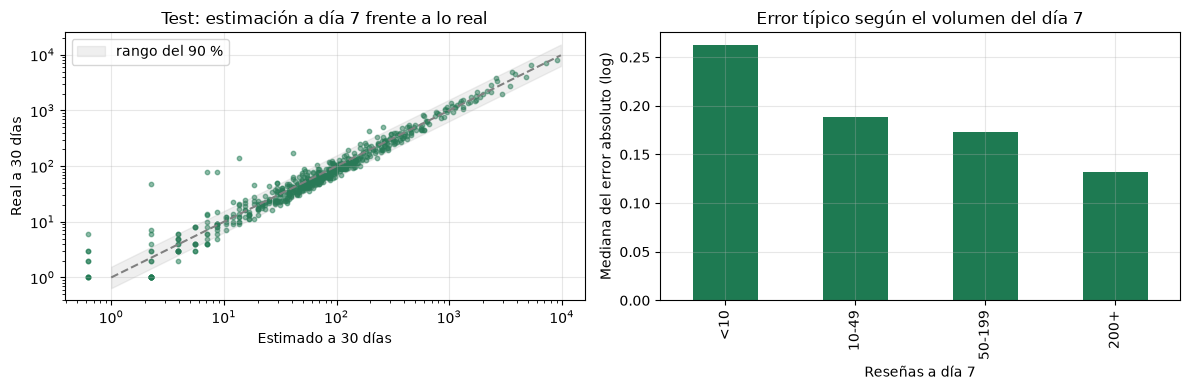

In [4]:
r7 = resultados[7]
te = m.preparar_variables(test, r7.generos)
pred = r7.modelo.predict(te[r7.variables.todas])
real = np.log1p(te["resenas_30d"])
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].scatter(np.expm1(pred), te["resenas_30d"], s=10, alpha=0.5, color="#1e7a52")
lim = [1, te["resenas_30d"].max() * 1.2]
axes[0].plot(lim, lim, color="grey", ls="--")
axes[0].fill_between(
    lim,
    np.array(lim) / np.exp(r7.q90),
    np.array(lim) * np.exp(r7.q90),
    color="grey",
    alpha=0.12,
    label="rango del 90 %",
)
axes[0].set(
    xscale="log",
    yscale="log",
    title="Test: estimación a día 7 frente a lo real",
    xlabel="Estimado a 30 días",
    ylabel="Real a 30 días",
)
axes[0].legend()
errores = pd.DataFrame(
    {"error": real - pred, "resenas_7d": te["resenas_7d"], "genero": te["genero"]}
)
tramos = pd.cut(
    errores["resenas_7d"],
    [-1, 9, 49, 199, np.inf],
    labels=["<10", "10-49", "50-199", "200+"],
)
errores.groupby(tramos, observed=True)["error"].apply(lambda e: e.abs().median()).plot(
    kind="bar", color="#1e7a52", ax=axes[1]
)
axes[1].set(
    title="Error típico según el volumen del día 7",
    xlabel="Reseñas a día 7",
    ylabel="Mediana del error absoluto (log)",
)
plt.tight_layout()
errores.groupby(tramos, observed=True)["error"].agg(
    n="size", sesgo="median", error_tipico=lambda e: e.abs().median()
).round(3)

In [5]:
errores.groupby("genero")["error"].agg(
    n="size", sesgo="median", error_tipico=lambda e: e.abs().median()
).round(3).sort_values("n", ascending=False)

,n,sesgo,error_tipico
genero,,,
Action,205,-0.126,0.186
Casual,152,-0.089,0.198
Adventure,127,-0.016,0.160
Simulation,49,-0.080,0.190
RPG,29,-0.143,0.208
Strategy,29,-0.123,0.230
Indie,9,-0.158,0.251
Otros,2,-0.239,0.239
Racing,2,-0.106,0.106


**Conclusión.** Entre 10 y 200 reseñas a día 7 el modelo sobreestima en este test (error mediano de −0,11 a −0,13 en log: lo real queda en torno a un 11 % por debajo de lo estimado); por debajo de 10 y por encima de 200 apenas hay sesgo. Los lanzamientos de julio a septiembre de 2026 crecieron algo menos tras su primera semana que los anteriores. El rango del 90 % absorbe ese desvío (cobertura del 92 %), pero conviene vigilarlo al reentrenar con datos nuevos. El error baja cuanto más volumen hay: con menos de 10 reseñas el error típico es 0,26 en log, con más de 200 baja a 0,13. Por género no hay ninguno claramente peor.

## 4. ¿Qué pesa en la estimación?

El modelo elegido a día 7 solo usa las reseñas, así que la pregunta se responde con Ridge, el candidato que ve todas las variables, entrenado con el mismo train.

In [6]:
tr7 = m.preparar_variables(train, r7.generos)
ridge = m.candidatos(r7.variables, None)["ridge"].fit(
    tr7[r7.variables.todas], np.log1p(tr7["resenas_30d"])
)
imp = permutation_importance(
    ridge,
    te[r7.variables.todas],
    real,
    n_repeats=30,
    random_state=m.SEMILLA,
    scoring="neg_mean_absolute_error",
)
nombres = ridge.named_steps["pre"].get_feature_names_out()
coef = pd.Series(ridge.named_steps["modelo"].coef_, index=nombres).round(3)
print("Coeficientes de Ridge (numéricas escaladas):")
print(coef[[n for n in nombres if n.startswith("num__")]])
pd.Series(imp.importances_mean, index=r7.variables.todas).sort_values(
    ascending=False
).round(4).to_frame("aumento del MAE al barajar")

Coeficientes de Ridge (numéricas escaladas):
num__log_resenas_7d      1.562
num__pct_positivas_7d    0.070
num__log_precio         -0.000
num__gratis             -0.032
dtype: float64


,aumento del MAE al barajar
log_resenas_7d,1.4647
pct_positivas_7d,0.0238
gratis,0.0032
genero,0.0015
log_precio,0.0000


**Conclusión.** Casi todo el peso está en las reseñas acumuladas: barajarlas multiplica el error, mientras que la positividad añade poco (0,02) y precio, gratuidad y género prácticamente nada una vez conocido el volumen. Es coherente con P5 del EDA (la opinión temprana importa, pero menos que el volumen) y explica por qué el ratio, que solo usa las reseñas, no pierde frente a modelos con más variables.

## 5. Antes de lanzar

In [7]:
previo = m.entrenar(ds, m.VARIABLES_PREVIAS)
print("Elegido por CV:", previo.nombre)
print(previo.cv.groupby("modelo")["mae_log"].agg(["mean", "std"]).round(3))
pd.DataFrame({previo.nombre: previo.test, **previo.test_baselines}).T.round(3)

Elegido por CV: gradient_boosting
                    mean    std
modelo                         
gradient_boosting  1.162  0.029
mediana            1.280  0.050
ridge              1.187  0.064


,mae_log,mediana_error_log,factor_error_tipico,spearman,dentro_de_x2,cobertura_90
gradient_boosting,1.143,0.940,2.560,0.351,0.379,0.92
mediana,1.212,0.872,2.392,NaN,0.406,NaN
ridge,1.139,0.936,2.549,0.354,0.389,NaN


El EDA (P7) mostró que los lanzamientos recientes de la muestra son más grandes por cómo se seleccionan. El mes de lanzamiento puede estar recogiendo ese efecto, así que se repite la evaluación sin él.

In [8]:
sin_mes = m.entrenar(
    ds, m.Variables(numericas=["log_precio", "gratis"], categoricas=["genero"])
)
pd.DataFrame(
    {
        f"sin mes ({sin_mes.nombre})": sin_mes.test,
        "mediana": sin_mes.test_baselines["mediana"],
    }
).T.round(3)

,mae_log,mediana_error_log,factor_error_tipico,spearman,dentro_de_x2,cobertura_90
sin mes (gradient_boosting),1.131,0.956,2.601,0.369,0.386,0.919
mediana,1.212,0.872,2.392,NaN,0.406,NaN


**Conclusión.** Antes del lanzamiento la evidencia es mixta. El candidato elegido (gradient boosting) baja el error medio frente a la mediana (1,14 frente a 1,21) y ordena algo los juegos (ρ = 0,36), pero empeora el error del juego típico (0,94 frente a 0,87) y acierta menos veces dentro de ×2 (37 % frente a 41 %). Sin el mes de lanzamiento, que arrastra el sesgo de selección, el resultado es el mismo. Por eso la app no da una cifra antes del lanzamiento y muestra el rango de juegos parecidos.

## 6. Conclusiones y limitaciones

- **Lo que funciona:** con las reseñas en inglés de la primera semana se estima el primer mes con un error típico de ×1,21 y un rango del 90 % que cubre el 92 % de los casos. A día 3 el error sube a ×1,34; a día 14 baja a ×1,09.
- **Lo que no:** antes de lanzar, precio, género y mes no permiten estimar un juego concreto mejor que la mediana de la muestra.
- **Limitaciones:** reseñas en inglés como aproximación a la actividad (no a las ventas); solo lanzamientos del último año por el límite de la API; muestra con al menos 50 reseñas, que deja fuera los lanzamientos casi sin público y favorece a los grandes entre los recientes; ligera sobreestimación en el periodo de test.
- **Siguiente paso:** reentrenar cada mes con los lanzamientos que vayan cerrando su primer mes y vigilar el sesgo del apartado 3.